In [ ]:
from google.colab import drive
import pandas as pd

# Mount Google Drive
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/Colab/world_cup_match_data.csv'

df_match = pd.read_csv(file_path)

file_path = '/content/drive/MyDrive/Colab/worldcup2026_elo.csv'

df_elo = pd.read_csv(file_path)

file_path = '/content/drive/MyDrive/Colab/worldcup2026_market_value_transfermarkt_million.csv'

df_marketvalue = pd.read_csv(file_path)

file_path = '/content/drive/MyDrive/Colab/team_appearances.csv'

df_team_appearances = pd.read_csv(file_path)

# 2018 and 2022 World Cup match stats
file_path = '/content/drive/MyDrive/Colab/international-fifa-world-cup-2018-russia-matches-2018-to-2018-stats.csv'
df_wc2018 = pd.read_csv(file_path)

file_path = '/content/drive/MyDrive/Colab/international-fifa-world-cup-2022-qatar-matches-2022-to-2022-stats.csv'
df_wc2022 = pd.read_csv(file_path)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Next cell take the value from Elo, market price and calculate experience from team_appeareances.

In [ ]:
match_to_elo = {
    'USMNT': 'United States',
    'Cape Verde Islands': 'Cape Verde',
    'Congo DR': 'Dem. Rep. of Congo',
}
mv_to_elo = {
    'Bosnia-Herzegovina': 'Bosnia and Herzegovina',
    'Czechia': 'Czech Republic',
    'Turkiye': 'Turkey',
    'Democratic Republic of the Congo': 'Dem. Rep. of Congo',
}

df = df_match.copy()
df['home_std'] = df['home_team_name'].str.strip().replace(match_to_elo)
df['away_std'] = df['away_team_name'].str.strip().replace(match_to_elo)

elo = df_elo.copy()
elo['Team1'] = elo['Team1'].str.strip().replace(match_to_elo)
elo['Team2'] = elo['Team2'].str.strip().replace(match_to_elo)

elo['match_key'] = elo.apply(lambda r: '|'.join(sorted([r['Team1'], r['Team2']])), axis=1)
df['match_key'] = df.apply(lambda r: '|'.join(sorted([r['home_std'], r['away_std']])), axis=1)

df = df.merge(elo, on='match_key', how='left', validate='one_to_one')

# If the home team is Team2 in the Elo file, swap the values
swap = df['home_std'] != df['Team1']
for c in ['before', 'after']:
    df[f'home_elo_{c}'] = df[f'Elo_team1_{c}'].where(~swap, df[f'Elo_team2_{c}'])
    df[f'away_elo_{c}'] = df[f'Elo_team2_{c}'].where(~swap, df[f'Elo_team1_{c}'])

df = df.drop(columns=['Team1', 'Team2', 'match_key']
             + [f'Elo_team{i}_{c}' for i in (1, 2) for c in ('before', 'after')])
mv = df_marketvalue.copy()
mv['Nation'] = mv['Nation'].str.strip().replace(mv_to_elo)
mv = mv.rename(columns={'Market Value (€ million)': 'market_value'})

df = df.merge(mv.rename(columns={'Nation': 'home_std', 'market_value': 'home_market_value'}),
              on='home_std', how='left')
df = df.merge(mv.rename(columns={'Nation': 'away_std', 'market_value': 'away_market_value'}),
              on='away_std', how='left')

# ---------- World Cup experience ----------
wc = df_team_appearances[
    df_team_appearances['tournament_name'].str.contains("Men's", na=False)
].copy()

hist_map = {
    'West Germany': 'Germany',
    'Zaire': 'Dem. Rep. of Congo',
    'Czechoslovakia': 'Czech Republic',
}
wc['team_std'] = wc['team_name'].str.strip().replace(hist_map)

exp = (wc.groupby('team_std')['tournament_id']
         .nunique()
         .rename('world_cup_experience'))

df['home_world_cup_experience'] = df['home_std'].map(exp).fillna(0).astype(int)
df['away_world_cup_experience'] = df['away_std'].map(exp).fillna(0).astype(int)

cols = ['attendance','home_elo_before', 'away_elo_before', 'home_market_value', 'away_market_value', 'home_world_cup_experience', 'away_world_cup_experience']
print(df.shape)
print(df[cols].isna().sum())
df[['home_team_name', 'away_team_name'] + cols].head()

(104, 76)
attendance                   0
home_elo_before              0
away_elo_before              0
home_market_value            0
away_market_value            0
home_world_cup_experience    0
away_world_cup_experience    0
dtype: int64


,home_team_name,away_team_name,attendance,home_elo_before,away_elo_before,home_market_value,away_market_value,home_world_cup_experience,away_world_cup_experience
0,Mexico,South Africa,80824,1875,1517,207.00,42.65,17,3
1,South Korea,Czech Republic,44985,1758,1740,146.65,179.20,11,9
2,Canada,Bosnia and Herzegovina,43002,1788,1595,130.63,152.20,2,1
3,USMNT,Paraguay,70492,1726,1834,241.80,160.15,11,8
4,Qatar,Switzerland,67966,1421,1891,20.25,309.40,1,12


Add column: recent_goals_scored, recent_goals_conceded, recent_shots, recent_sot_pct(shot on target percentage), recent_clean_sheet_pct, recent_possession

In [ ]:
import numpy as np

df = df.sort_values('timestamp').reset_index(drop=True)

def build_team_history(d, home_col, away_col):
    """One row per team per match with that match's goals, shots, shots-on-target %, clean sheet and possession."""
    home = d[['timestamp', home_col, 'home_team_goal_count', 'away_team_goal_count',
              'home_team_shots', 'home_team_shots_on_target', 'home_team_possession']].copy()
    away = d[['timestamp', away_col, 'away_team_goal_count', 'home_team_goal_count',
              'away_team_shots', 'away_team_shots_on_target', 'away_team_possession']].copy()
    cols = ['timestamp', 'team', 'goals_scored', 'goals_conceded', 'shots', 'shots_on_target', 'possession']
    home.columns = cols; away.columns = cols
    th = pd.concat([home, away]).sort_values(['team', 'timestamp']).reset_index(drop=True)
    th['sot_pct'] = th['shots_on_target'] / th['shots'].replace(0, np.nan) * 100
    th['clean_sheet_pct'] = (th['goals_conceded'] == 0) * 100
    return th

team_history = build_team_history(df, 'home_std', 'away_std')

stat_map = {
    'recent_goals_scored':     'goals_scored',
    'recent_goals_conceded':   'goals_conceded',
    'recent_shots':            'shots',
    'recent_sot_pct':          'sot_pct',
    'recent_clean_sheet_pct':  'clean_sheet_pct',
    'recent_possession':       'possession',
}
g = team_history.groupby('team')
for new_col, old_col in stat_map.items():
    team_history[new_col] = g[old_col].transform(lambda x: x.shift(1).expanding().mean())

stat_cols = list(stat_map.keys())
stats = team_history[['timestamp', 'team'] + stat_cols]

for side in ['home', 'away']:
    df = df.merge(
        stats.rename(columns={'team': f'{side}_std', **{c: f'{side}_{c}' for c in stat_cols}}),
        on=['timestamp', f'{side}_std'], how='left'
    )
# Check how many was null (First match of a team should always be null)
print(df[[f'{s}_{c}' for c in stat_cols for s in ('home', 'away')]].isna().sum())

home_recent_goals_scored       24
away_recent_goals_scored       24
home_recent_goals_conceded     24
away_recent_goals_conceded     24
home_recent_shots              24
away_recent_shots              24
home_recent_sot_pct            24
away_recent_sot_pct            24
home_recent_clean_sheet_pct    24
away_recent_clean_sheet_pct    24
home_recent_possession         24
away_recent_possession         24
dtype: int64


Imputation: Use data from 2018 and 2022 World Cup. If there are still null, impute it with mean from 2026 World Cup.

In [ ]:
# --------------------------------------------------
# IMPUTATION of the first-match NULLs
#   1) the team's mean over the 2018 + 2022 World Cups
#   2) if still NULL -> mean of the 2026 values
# --------------------------------------------------
hist_matches = pd.concat([df_wc2018, df_wc2022], ignore_index=True)
for c in ['home_team_name', 'away_team_name']:
    hist_matches[c] = hist_matches[c].str.strip().replace(match_to_elo)

hist_history = build_team_history(hist_matches, 'home_team_name', 'away_team_name')
hist_mean = (hist_history.groupby('team')[list(stat_map.values())].mean()
             .rename(columns={old: new for new, old in stat_map.items()}))

mean_2026 = {c: pd.concat([df[f'home_{c}'], df[f'away_{c}']]).mean() for c in stat_cols}

report = []
for c in stat_cols:
    n_null = n_hist = 0
    for side in ['home', 'away']:
        col = f'{side}_{c}'
        isnull = df[col].isna()
        n_null += isnull.sum()
        df[col] = df[col].fillna(df[f'{side}_std'].map(hist_mean[c]))      # step 1: 2018 + 2022 team mean
        n_hist += (isnull & df[col].notna()).sum()
        df[col] = df[col].fillna(mean_2026[c])                             # step 2: 2026 mean
    report.append({'stat': c, 'null values': n_null, 'filled from 2018+2022': n_hist,
                   'filled from 2026 mean': n_null - n_hist})
display(pd.DataFrame(report).set_index('stat'))
print("Remaining NULLs:", int(df[[f'{s}_{c}' for c in stat_cols for s in ('home', 'away')]].isna().sum().sum()))

,null values,filled from 2018+2022,filled from 2026 mean
stat,,,
recent_goals_scored,48,30,18
recent_goals_conceded,48,30,18
recent_shots,48,30,18
recent_sot_pct,48,30,18
recent_clean_sheet_pct,48,30,18
recent_possession,48,30,18


Remaining NULLs: 0


Add more column as differences between 2 teams

In [ ]:
# --------------------------------------------------
# Create the differences (home - away)
# --------------------------------------------------
df['elo_difference'] = df['home_elo_before'] - df['away_elo_before']
df['market_value_difference'] = df['home_market_value'] - df['away_market_value']
df['recent_avg_goal_score_difference'] = df['home_recent_goals_scored'] - df['away_recent_goals_scored']
df['recent_avg_goals_conceded_difference'] = df['home_recent_goals_conceded'] - df['away_recent_goals_conceded']
df['tournament_experience_difference'] = df['home_world_cup_experience'] - df['away_world_cup_experience']
df['recent_avg_shots_difference'] = df['home_recent_shots'] - df['away_recent_shots']
df['shots_on_target_percentage_difference'] = df['home_recent_sot_pct'] - df['away_recent_sot_pct']
df['recent_avg_possession_difference'] = df['home_recent_possession'] - df['away_recent_possession']
df['recent_clean_sheet_pct_difference'] = df['home_recent_clean_sheet_pct'] - df['away_recent_clean_sheet_pct']

In [ ]:
# --------------------------------------------------
# CREATE TARGET VARIABLE: GOALS DIFFERENCE
# --------------------------------------------------

df['goals_difference'] = (
    df['home_team_goal_count'] -
    df['away_team_goal_count']
)


Clean up df_final

In [ ]:
match_cols = [c for c in df_match.select_dtypes('number').columns if c != 'Game Week']
match_cols = [c for c in match_cols if df_match[c].notna().any()]          # drops the all-empty referee column

diff_cols = [
    'elo_difference', 'market_value_difference',
    'recent_avg_goal_score_difference', 'recent_avg_goals_conceded_difference',
    'recent_avg_shots_difference', 'shots_on_target_percentage_difference',
    'recent_avg_possession_difference', 'recent_clean_sheet_pct_difference',
    'tournament_experience_difference',
]
raw_cols = [f'{side}_{c}' for c in stat_cols for side in ('home', 'away')]
elo_mv_exp_cols = ['home_elo_before', 'away_elo_before', 'home_elo_after', 'away_elo_after',
                   'home_market_value', 'away_market_value',
                   'home_world_cup_experience', 'away_world_cup_experience']

df_final = df[['home_team_name', 'away_team_name'] + match_cols + elo_mv_exp_cols + raw_cols + diff_cols].copy()
df_final['is_knockout'] = df['Game Week'].isna().astype(int)       # Game Week is empty for the 32 knock-out matches
df_final['goals_difference'] = df['goals_difference']

# Matchday 1: the "Pre-Match" tournament-to-date columns are stored as 0.00 because nothing has been
# played yet (an unknown, not a real zero). Treat them as missing and fill with the 2026 mean of matchdays 2-3.
md1 = df['Game Week'] == 1
to_date_cols = [c for c in match_cols if 'pre_match' in c.lower() or 'Pre-Match' in c]
for c in to_date_cols:
    df_final.loc[md1, c] = np.nan
    df_final[c] = df_final[c].fillna(df_final.loc[~md1, c].mean())

print(df_final.shape)
print("NULLs left:", int(df_final.isna().sum().sum()))
df_final.head()

(104, 90)
NULLs left: 0


,home_team_name,away_team_name,timestamp,attendance,Pre-Match PPG (Home),Pre-Match PPG (Away),home_ppg,away_ppg,home_team_goal_count,away_team_goal_count,...,market_value_difference,recent_avg_goal_score_difference,recent_avg_goals_conceded_difference,recent_avg_shots_difference,shots_on_target_percentage_difference,recent_avg_possession_difference,recent_clean_sheet_pct_difference,tournament_experience_difference,is_knockout,goals_difference
0,Mexico,South Africa,1781204400,80824,1.7085,1.606875,2.40,1.00,2,0,...,164.35,-1.013884,0.016190,-1.723021,-2.973416,1.206964,-1.782738,14,0,2
1,South Korea,Czech Republic,1781229600,44985,1.7085,1.606875,1.00,0.33,2,1,...,-32.55,-0.585313,0.301905,-3.294449,4.502441,-7.507321,-1.782738,2,0,1
2,Canada,Bosnia and Herzegovina,1781290800,43002,1.7085,1.606875,1.40,1.00,1,1,...,-21.57,-1.061503,1.063810,-1.961116,-22.112611,2.111726,-30.354167,1,0,0
3,USMNT,Paraguay,1781312400,70492,1.7085,1.606875,1.80,1.00,4,1,...,81.65,-0.978170,-0.269524,-2.044449,-6.359809,1.278393,19.645833,3,0,3
4,Qatar,Switzerland,1781377200,67966,1.7085,1.606875,0.33,1.83,1,1,...,-289.15,-0.916667,0.583333,-2.083333,-4.523810,-10.208333,-12.500000,-11,0,0


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

## EDA: eliminate the variables not available before the match, then choose the best 8

**Step 1 - availability.** Every column of `df_final` is checked. A variable may only be used if it is known *before* kick-off, otherwise the model would "predict" a match using information from the match itself. Two columns that look pre-match are tested explicitly: `home_ppg` / `away_ppg` and `Pre-Match xG`.

**Step 2 - EDA.** For the remaining variables we write an expected sign first, then look at the scatter plot and the Pearson r against `goals_difference`, and keep the **8 strongest**, skipping any variable that is almost a copy of one already chosen (**VIF ≥ 10**).

In [ ]:
# --- test 1: are home_ppg / away_ppg the FULL-tournament points per game (they would contain the match itself)?
pts = []
for _, r in df.iterrows():
    h, a = r.home_team_goal_count, r.away_team_goal_count
    pts += [(r.home_team_name, 3 if h > a else 1 if h == a else 0), (r.away_team_name, 3 if a > h else 1 if h == a else 0)]
full_ppg = pd.DataFrame(pts, columns=['team', 'pts']).groupby('team').pts.mean()
d_ppg = max((df.home_ppg - df.home_team_name.map(full_ppg)).abs().max(), (df.away_ppg - df.away_team_name.map(full_ppg)).abs().max())
print(f"1) home_ppg/away_ppg vs full-tournament PPG recomputed from results: max difference = {d_ppg:.3f} -> they contain the match itself = LEAK")

# --- test 2: is 'Pre-Match PPG' built from EARLIER matches only?
cum, bad, tot = {}, 0, 0
for _, r in df.iterrows():
    for side, col in [('home', 'Pre-Match PPG (Home)'), ('away', 'Pre-Match PPG (Away)')]:
        prev = cum.get(r[f'{side}_team_name'], [])
        if prev: tot += 1; bad += abs(np.mean(prev) - r[col]) > 0.02
    h, a = r.home_team_goal_count, r.away_team_goal_count
    cum.setdefault(r.home_team_name, []).append(3 if h > a else 1 if h == a else 0)
    cum.setdefault(r.away_team_name, []).append(3 if a > h else 1 if h == a else 0)
print(f"2) 'Pre-Match PPG' vs PPG from earlier matches only: {tot - bad} of {tot} equal -> genuinely pre-match")

# --- test 3: is 'Pre-Match xG' the running mean of earlier matches' team_a_xg / team_b_xg (i.e. team_a_xg is the match's own xG)?
hist_xg, bad, tot = {}, 0, 0
for _, r in df.iterrows():
    for side, col in [('home', 'Home Team Pre-Match xG'), ('away', 'Away Team Pre-Match xG')]:
        prev = hist_xg.get(r[f'{side}_team_name'], [])
        if prev: tot += 1; bad += abs(np.mean(prev) - r[col]) > 0.03
    hist_xg.setdefault(r.home_team_name, []).append(r.team_a_xg); hist_xg.setdefault(r.away_team_name, []).append(r.team_b_xg)
print(f"3) 'Pre-Match xG' equals the running mean of earlier team_a_xg/team_b_xg in {tot - bad} of {tot} cases -> team_a_xg/team_b_xg are post-match, Pre-Match xG is pre-match")

# Print verdict for every variable
pre_match = (to_date_cols
             + [c for c in match_cols if c.startswith('odds_')]          # bookmaker odds are published before kick-off
             + ['is_knockout', 'home_elo_before', 'away_elo_before', 'home_market_value', 'away_market_value',
                'home_world_cup_experience', 'away_world_cup_experience']
             + raw_cols + diff_cols)
leaky = ['home_ppg', 'away_ppg']
identifier = ['timestamp']

verdict = []
for c in [c for c in df_final.columns if c not in ('home_team_name', 'away_team_name', 'goals_difference')]:
    if c in identifier:  v, why = 'ELIMINATE', 'identifier / time stamp'
    elif c in leaky:     v, why = 'ELIMINATE', 'leak: full-tournament PPG contains the match result (test 1)'
    elif c in pre_match: v, why = 'KEEP', 'known before kick-off'
    else:                v, why = 'ELIMINATE', 'only known during / after the match (goals, shots, cards, possession, xG of the match, attendance, Elo after ...)'
    verdict.append((c, v, why))
verdict = pd.DataFrame(verdict, columns=['column', 'verdict', 'reason'])
print()
print(verdict.verdict.value_counts().to_string())
display(verdict[verdict.verdict == 'ELIMINATE'].reset_index(drop=True))

kept_cols = verdict.loc[verdict.verdict == 'KEEP', 'column'].tolist()
candidates = df_final[kept_cols]
target = df_final['goals_difference']
assert candidates.isna().sum().sum() == 0 and (candidates.nunique() > 1).all()
print("Candidate variables available before the match:", len(kept_cols))

1) home_ppg/away_ppg vs full-tournament PPG recomputed from results: max difference = 0.005 -> they contain the match itself = LEAK
2) 'Pre-Match PPG' vs PPG from earlier matches only: 160 of 160 equal -> genuinely pre-match
3) 'Pre-Match xG' equals the running mean of earlier team_a_xg/team_b_xg in 160 of 160 cases -> team_a_xg/team_b_xg are post-match, Pre-Match xG is pre-match

verdict
KEEP         53
ELIMINATE    34


,column,verdict,reason
0,timestamp,ELIMINATE,identifier / time stamp
1,attendance,ELIMINATE,"only known during / after the match (goals, sh..."
2,home_ppg,ELIMINATE,leak: full-tournament PPG contains the match r...
3,away_ppg,ELIMINATE,leak: full-tournament PPG contains the match r...
4,home_team_goal_count,ELIMINATE,"only known during / after the match (goals, sh..."
5,away_team_goal_count,ELIMINATE,"only known during / after the match (goals, sh..."
6,total_goal_count,ELIMINATE,"only known during / after the match (goals, sh..."
7,total_goals_at_half_time,ELIMINATE,"only known during / after the match (goals, sh..."
8,home_team_goal_count_half_time,ELIMINATE,"only known during / after the match (goals, sh..."
9,away_team_goal_count_half_time,ELIMINATE,"only known during / after the match (goals, sh..."


Candidate variables available before the match: 53


,expected sign,pearson r,p-value,sign as expected
variable,,,,
elo_difference,+,0.6267,0.0000,True
market_value_difference,+,0.5923,0.0000,True
odds_ft_away_team_win,+,0.5388,0.0000,True
tournament_experience_difference,+,0.5330,0.0000,True
odds_ft_home_team_win,-,-0.5207,0.0000,True
away_elo_before,-,-0.5112,0.0000,True
away_market_value,-,-0.4743,0.0000,True
away_world_cup_experience,-,-0.4407,0.0000,True
recent_avg_possession_difference,+,0.4101,0.0000,True


Hypotheses with an expected sign confirmed by the sign of r: 35 of 35


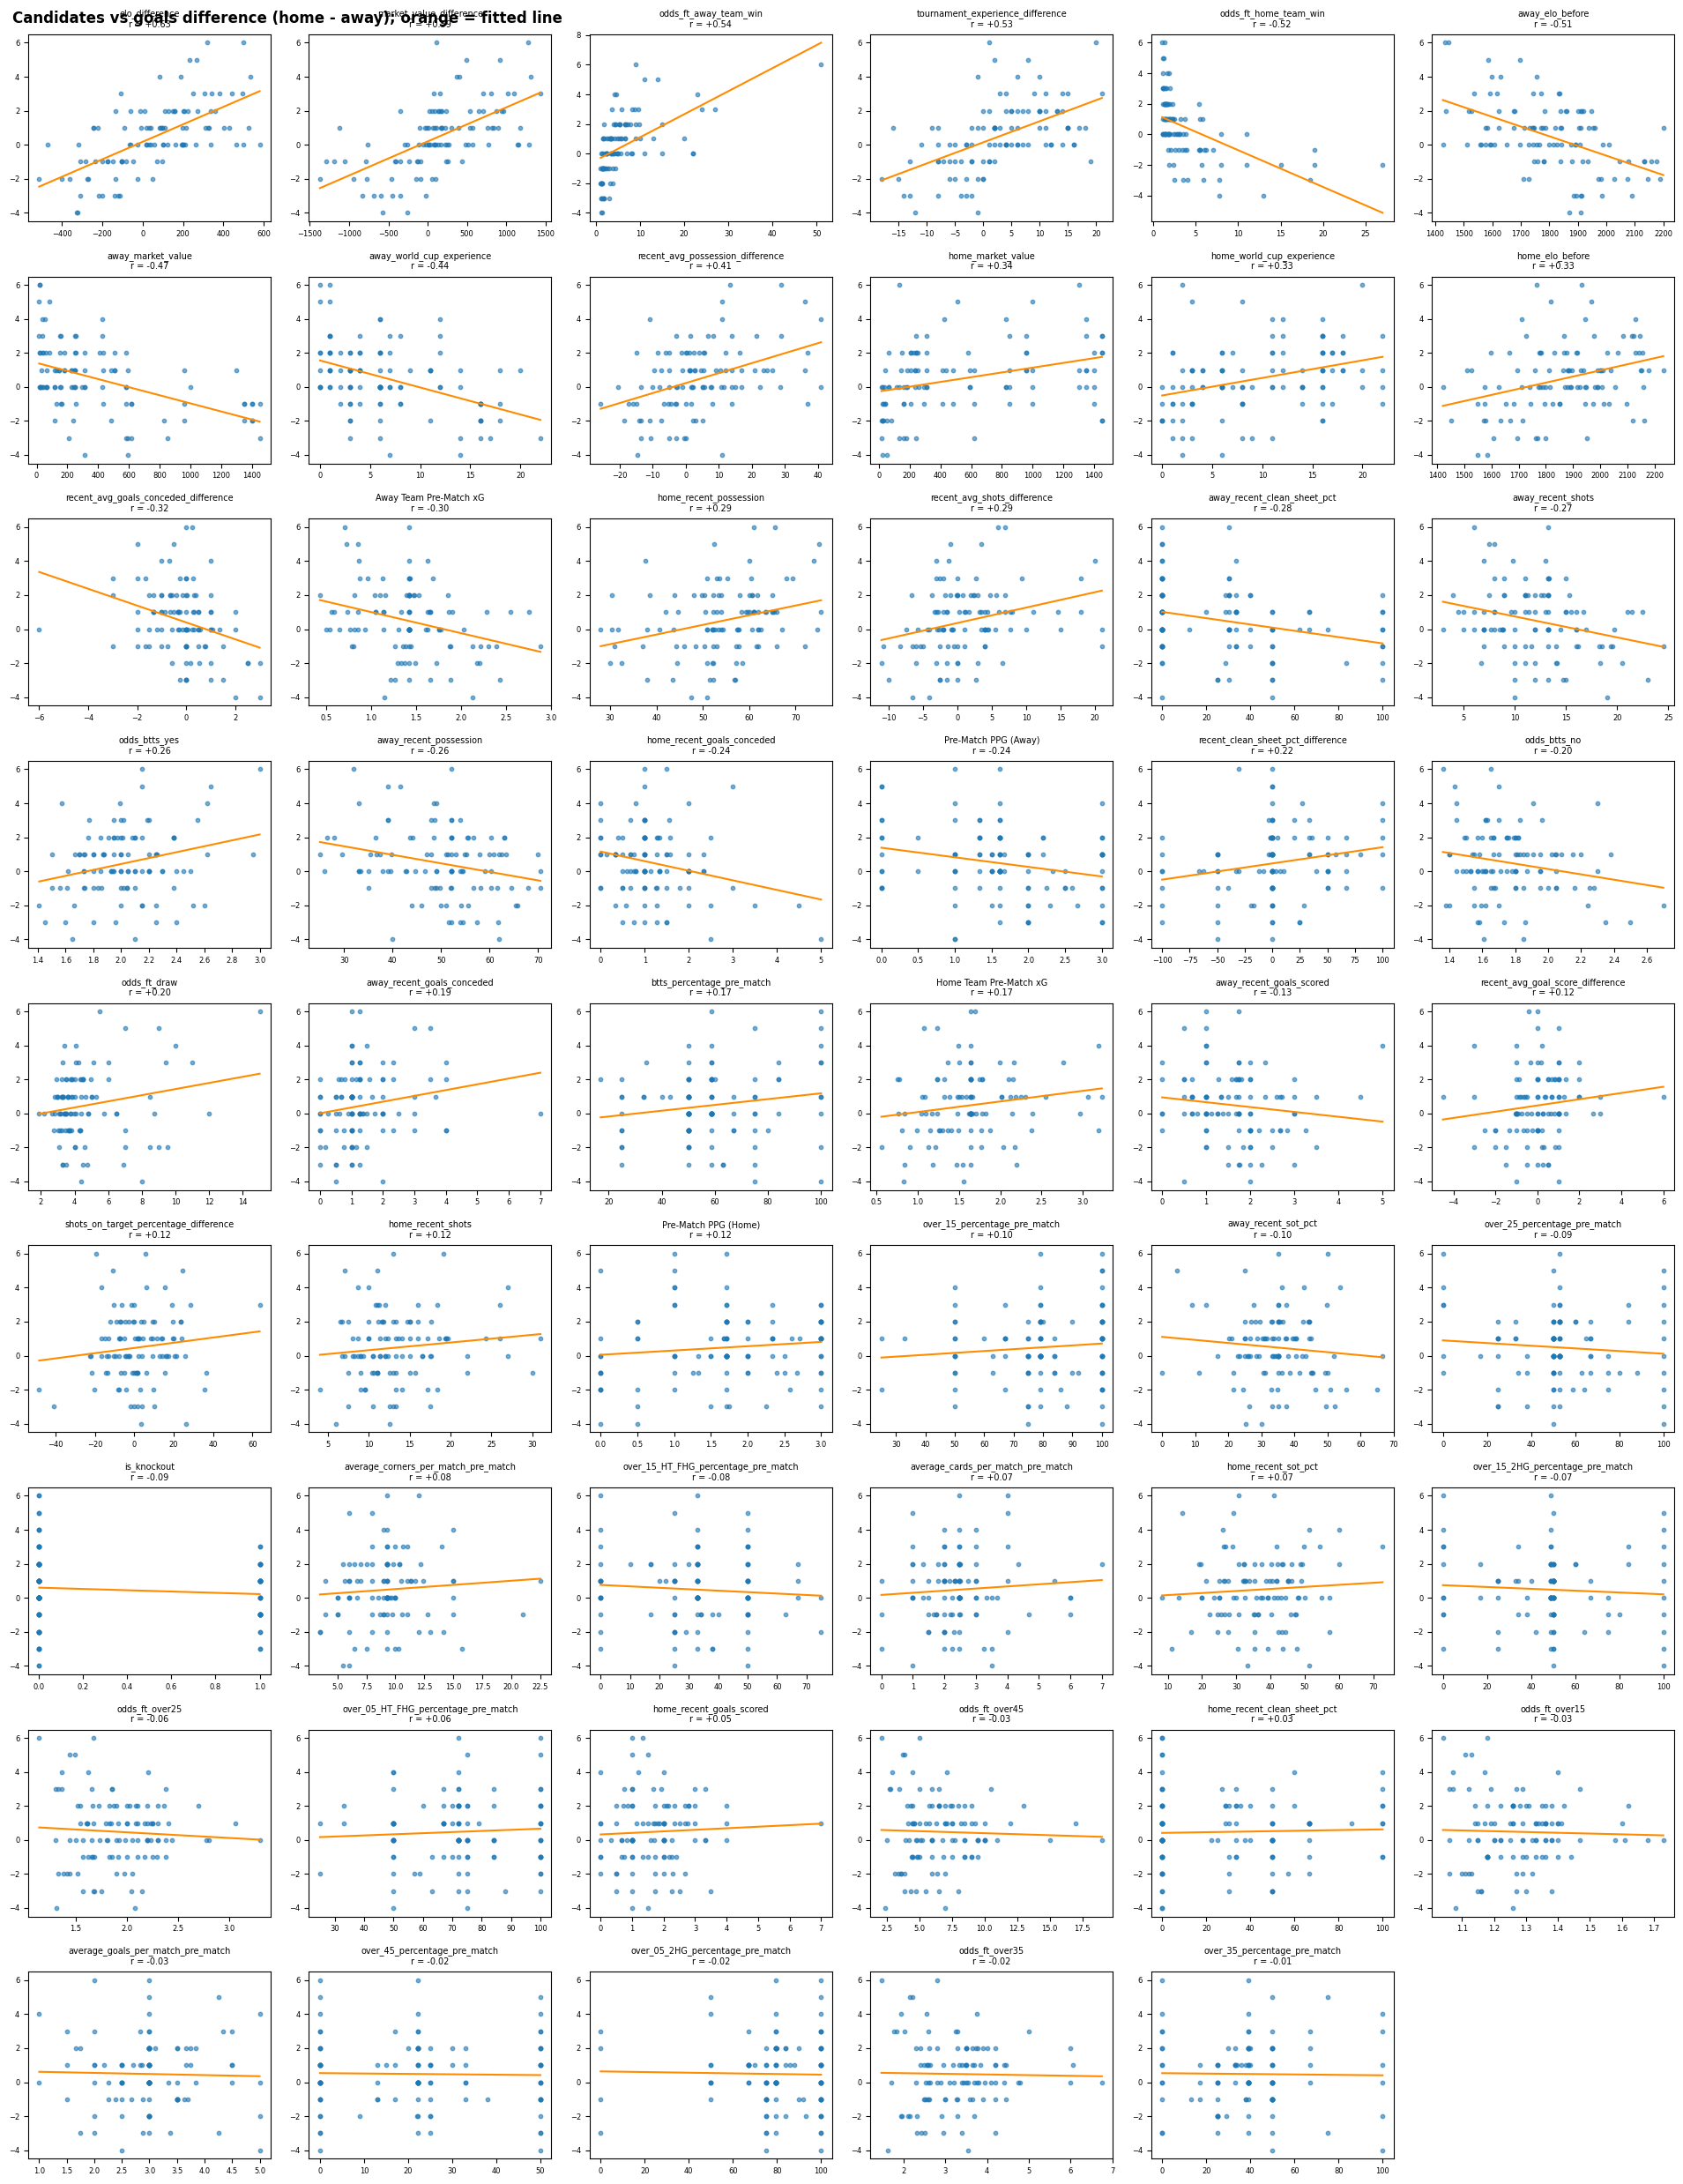

In [ ]:
from scipy import stats
from sklearn.linear_model import LinearRegression

# expected sign of the correlation with goals_difference (home - away), written BEFORE looking at the data.
# 0 = no clear direction for the margin (e.g. a scoring-environment variable)
hyp = {
    'Pre-Match PPG (Home)': (+1, 'better results so far -> stronger home side'),
    'Pre-Match PPG (Away)': (-1, 'better results so far -> stronger away side'),
    'Home Team Pre-Match xG': (+1, 'home side creates more chances'),
    'Away Team Pre-Match xG': (-1, 'away side creates more chances'),
    'odds_ft_home_team_win': (-1, 'higher odds = home side less likely to win'),
    'odds_ft_draw': (+1, 'long draw odds = mismatch = bigger margin'),
    'odds_ft_away_team_win': (+1, 'higher odds = away side less likely to win'),
    'is_knockout': (-1, 'knock-out games are cagier'),
    'home_elo_before': (+1, 'stronger home side'), 'away_elo_before': (-1, 'stronger away side'),
    'home_market_value': (+1, 'more valuable home squad'), 'away_market_value': (-1, 'more valuable away squad'),
    'home_world_cup_experience': (+1, 'more World Cup experience'), 'away_world_cup_experience': (-1, 'more World Cup experience'),
    'elo_difference': (+1, 'stronger rated home side wins by more'),
    'market_value_difference': (+1, 'more valuable squad wins by more'),
    'recent_avg_goal_score_difference': (+1, 'scores more than the opponent so far'),
    'recent_avg_goals_conceded_difference': (-1, 'concedes more than the opponent so far'),
    'recent_avg_shots_difference': (+1, 'creates more shots'),
    'shots_on_target_percentage_difference': (+1, 'more accurate shooting'),
    'recent_avg_possession_difference': (+1, 'controls the ball more'),
    'recent_clean_sheet_pct_difference': (+1, 'keeps more clean sheets'),
    'tournament_experience_difference': (+1, 'more World Cup experience'),
}
good_home = {'recent_goals_scored': +1, 'recent_goals_conceded': -1, 'recent_shots': +1,
             'recent_sot_pct': +1, 'recent_clean_sheet_pct': +1, 'recent_possession': +1}
for c, s in good_home.items():
    hyp[f'home_{c}'] = (s,  'home team form: same direction as the home edge')
    hyp[f'away_{c}'] = (-s, 'away team form: opposite direction to the home edge')
for c in kept_cols:                                     # everything else: scoring-environment variables
    hyp.setdefault(c, (0, 'scoring environment (goals / corners / cards / over-under / BTTS): no clear direction for the margin'))

rows = []
for c in candidates.columns:
    r, p = stats.pearsonr(candidates[c], target)
    rows.append({'variable': c, 'expected sign': {1: '+', -1: '-', 0: '?'}[hyp[c][0]], 'pearson r': r, 'p-value': p,
                 'sign as expected': (np.sign(r) == hyp[c][0]) if hyp[c][0] != 0 else None})
eda = pd.DataFrame(rows).set_index('variable').sort_values('pearson r', key=abs, ascending=False)
display(eda.round(4))
signed = eda['sign as expected'].dropna()
print("Hypotheses with an expected sign confirmed by the sign of r:", int(signed.astype(bool).sum()), "of", len(signed))

# scatter plots with fitted line, strongest first
n = len(eda); ncols = 6; nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.8 * nrows)); axes = axes.flatten()
for ax, c in zip(axes, eda.index):
    ax.scatter(candidates[c], target, s=10, alpha=.6)
    b = np.polyfit(candidates[c], target, 1); xs = np.linspace(candidates[c].min(), candidates[c].max(), 20)
    ax.plot(xs, np.polyval(b, xs), color='darkorange', lw=1.5)
    ax.set_title(f"{c}\nr = {eda.loc[c, 'pearson r']:+.2f}", fontsize=7); ax.tick_params(labelsize=6)
for ax in axes[n:]: ax.axis('off')
plt.suptitle('Candidates vs goals difference (home - away); orange = fitted line', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

SELECTED (8): ['elo_difference', 'market_value_difference', 'odds_ft_away_team_win', 'tournament_experience_difference', 'odds_ft_home_team_win', 'away_elo_before', 'away_market_value', 'away_world_cup_experience']
Highest VIF in the selected set: 8.72


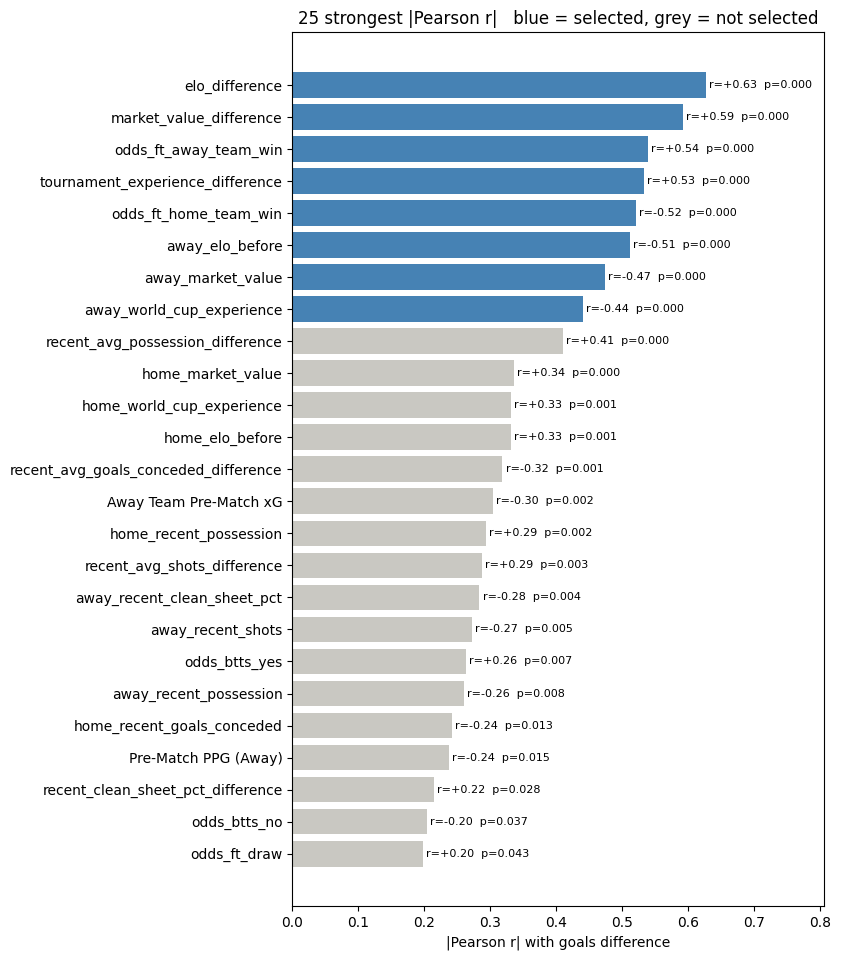

In [ ]:
def max_vif(X):
    """Largest variance-inflation factor in X (inf if a column is an exact copy of the others)."""
    out = []
    for c in X.columns:
        others = X.drop(columns=c)
        r2 = LinearRegression().fit(others, X[c]).score(others, X[c])
        out.append(np.inf if r2 > 1 - 1e-9 else 1 / (1 - r2))
    return max(out)

def select_top_k(X, tab, k=8, vif_limit=10):
    chosen = []
    for c in tab.index:                                   # strongest |r| first
        if len(chosen) == k: break
        if chosen and max_vif(X[chosen + [c]]) >= vif_limit: continue   # would create serious multicollinearity
        chosen.append(c)
    return chosen

selected_features = select_top_k(candidates, eda, k=8, vif_limit=10)

print("SELECTED (8):", selected_features)
print("Highest VIF in the selected set: %.2f" % max_vif(candidates[selected_features]))

# bar chart of the 25 strongest |r|: blue = selected
t = eda.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, .34 * len(t) + 1.2))
ax.barh(t.index, t['pearson r'].abs(), color=['steelblue' if v in selected_features else '#c9c8c2' for v in t.index])
for i, (r_, p_) in enumerate(zip(t['pearson r'], t['p-value'])):
    ax.text(abs(r_) + .005, i, f'r={r_:+.2f}  p={p_:.3f}', va='center', fontsize=8)
ax.set(title='25 strongest |Pearson r|   blue = selected, grey = not selected', xlabel='|Pearson r| with goals difference')
ax.set_xlim(0, t['pearson r'].abs().max() + .18)
plt.tight_layout(); plt.show()

## Train / test split (80% / 20%)

We split **first**, before any optimisation. Every step below is *fitted on the training set only*
(outlier bounds, Yeo-Johnson lambdas, scaler mean/std) and then *applied* to the test set,
so the test set never influences the model. The test set is never filtered, so every stage is scored on the same 20% of matches.

In [ ]:
feature_cols = selected_features   # the 8 variables nominated by the EDA above

X_train, X_test, y_train, y_test = train_test_split(
    df_final[feature_cols],
    df_final['goals_difference'],
    test_size=0.2,
    random_state=42
)

print("Train:", X_train.shape, " Test:", X_test.shape)

# ---- helpers ----
def print_equation(model, target_name):
    equation = f"{target_name} = {model.params['const']:.4f}"
    for variable in model.params.index:
        if variable == 'const':
            continue
        coefficient = model.params[variable]
        if coefficient >= 0:
            equation += f" + {coefficient:.4f} ({variable})"
        else:
            equation += f" - {abs(coefficient):.4f} ({variable})"
    print("\nRegression equation:")
    print(equation)

results = []   # one row per optimisation stage

def fit_and_evaluate(stage, X_tr, y_tr, X_te, y_te):
    """Fit OLS on the (current) training data, score on train and on the untouched test set."""
    model = sm.OLS(y_tr, sm.add_constant(X_tr, has_constant='add')).fit()
    pred_tr = model.predict(sm.add_constant(X_tr, has_constant='add'))
    pred_te = model.predict(sm.add_constant(X_te, has_constant='add'))
    results.append({
        'Stage': stage,
        'Train R2': r2_score(y_tr, pred_tr),
        'Test R2': r2_score(y_te, pred_te),
        'Test RMSE': np.sqrt(mean_squared_error(y_te, pred_te)),
        'Test MAE': mean_absolute_error(y_te, pred_te),
    })
    return model, pred_te

# ---- Baseline (no optimisation) ----
model, _ = fit_and_evaluate('0. Baseline', X_train, y_train, X_test, y_test)
print_equation(model, 'Goals Difference')

Train: (83, 8)  Test: (21, 8)

Regression equation:
Goals Difference = -0.1034 + 0.0015 (elo_difference) + 0.0003 (market_value_difference) + 0.0759 (odds_ft_away_team_win) + 0.0026 (tournament_experience_difference) - 0.0715 (odds_ft_home_team_win) + 0.0003 (away_elo_before) - 0.0014 (away_market_value) + 0.0459 (away_world_cup_experience)


## Optimization 1: Remove outliers (training set only)

In [ ]:
Q1 = y_train.quantile(0.25)
Q3 = y_train.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

mask = (y_train >= lower_bound) & (y_train <= upper_bound)

X_train_cur = X_train[mask].copy()
y_train_cur = y_train[mask].copy()
X_test_cur  = X_test.copy()

print("Training observations after removing outliers:", len(X_train_cur), f"(removed {(~mask).sum()})")

model, _ = fit_and_evaluate('1. + Outlier removal', X_train_cur, y_train_cur, X_test_cur, y_test)
print_equation(model, "Goals Difference")

Training observations after removing outliers: 83 (removed 0)

Regression equation:
Goals Difference = -0.1034 + 0.0015 (elo_difference) + 0.0003 (market_value_difference) + 0.0759 (odds_ft_away_team_win) + 0.0026 (tournament_experience_difference) - 0.0715 (odds_ft_home_team_win) + 0.0003 (away_elo_before) - 0.0014 (away_market_value) + 0.0459 (away_world_cup_experience)


## Optimization 2: Check for non-linear relationships

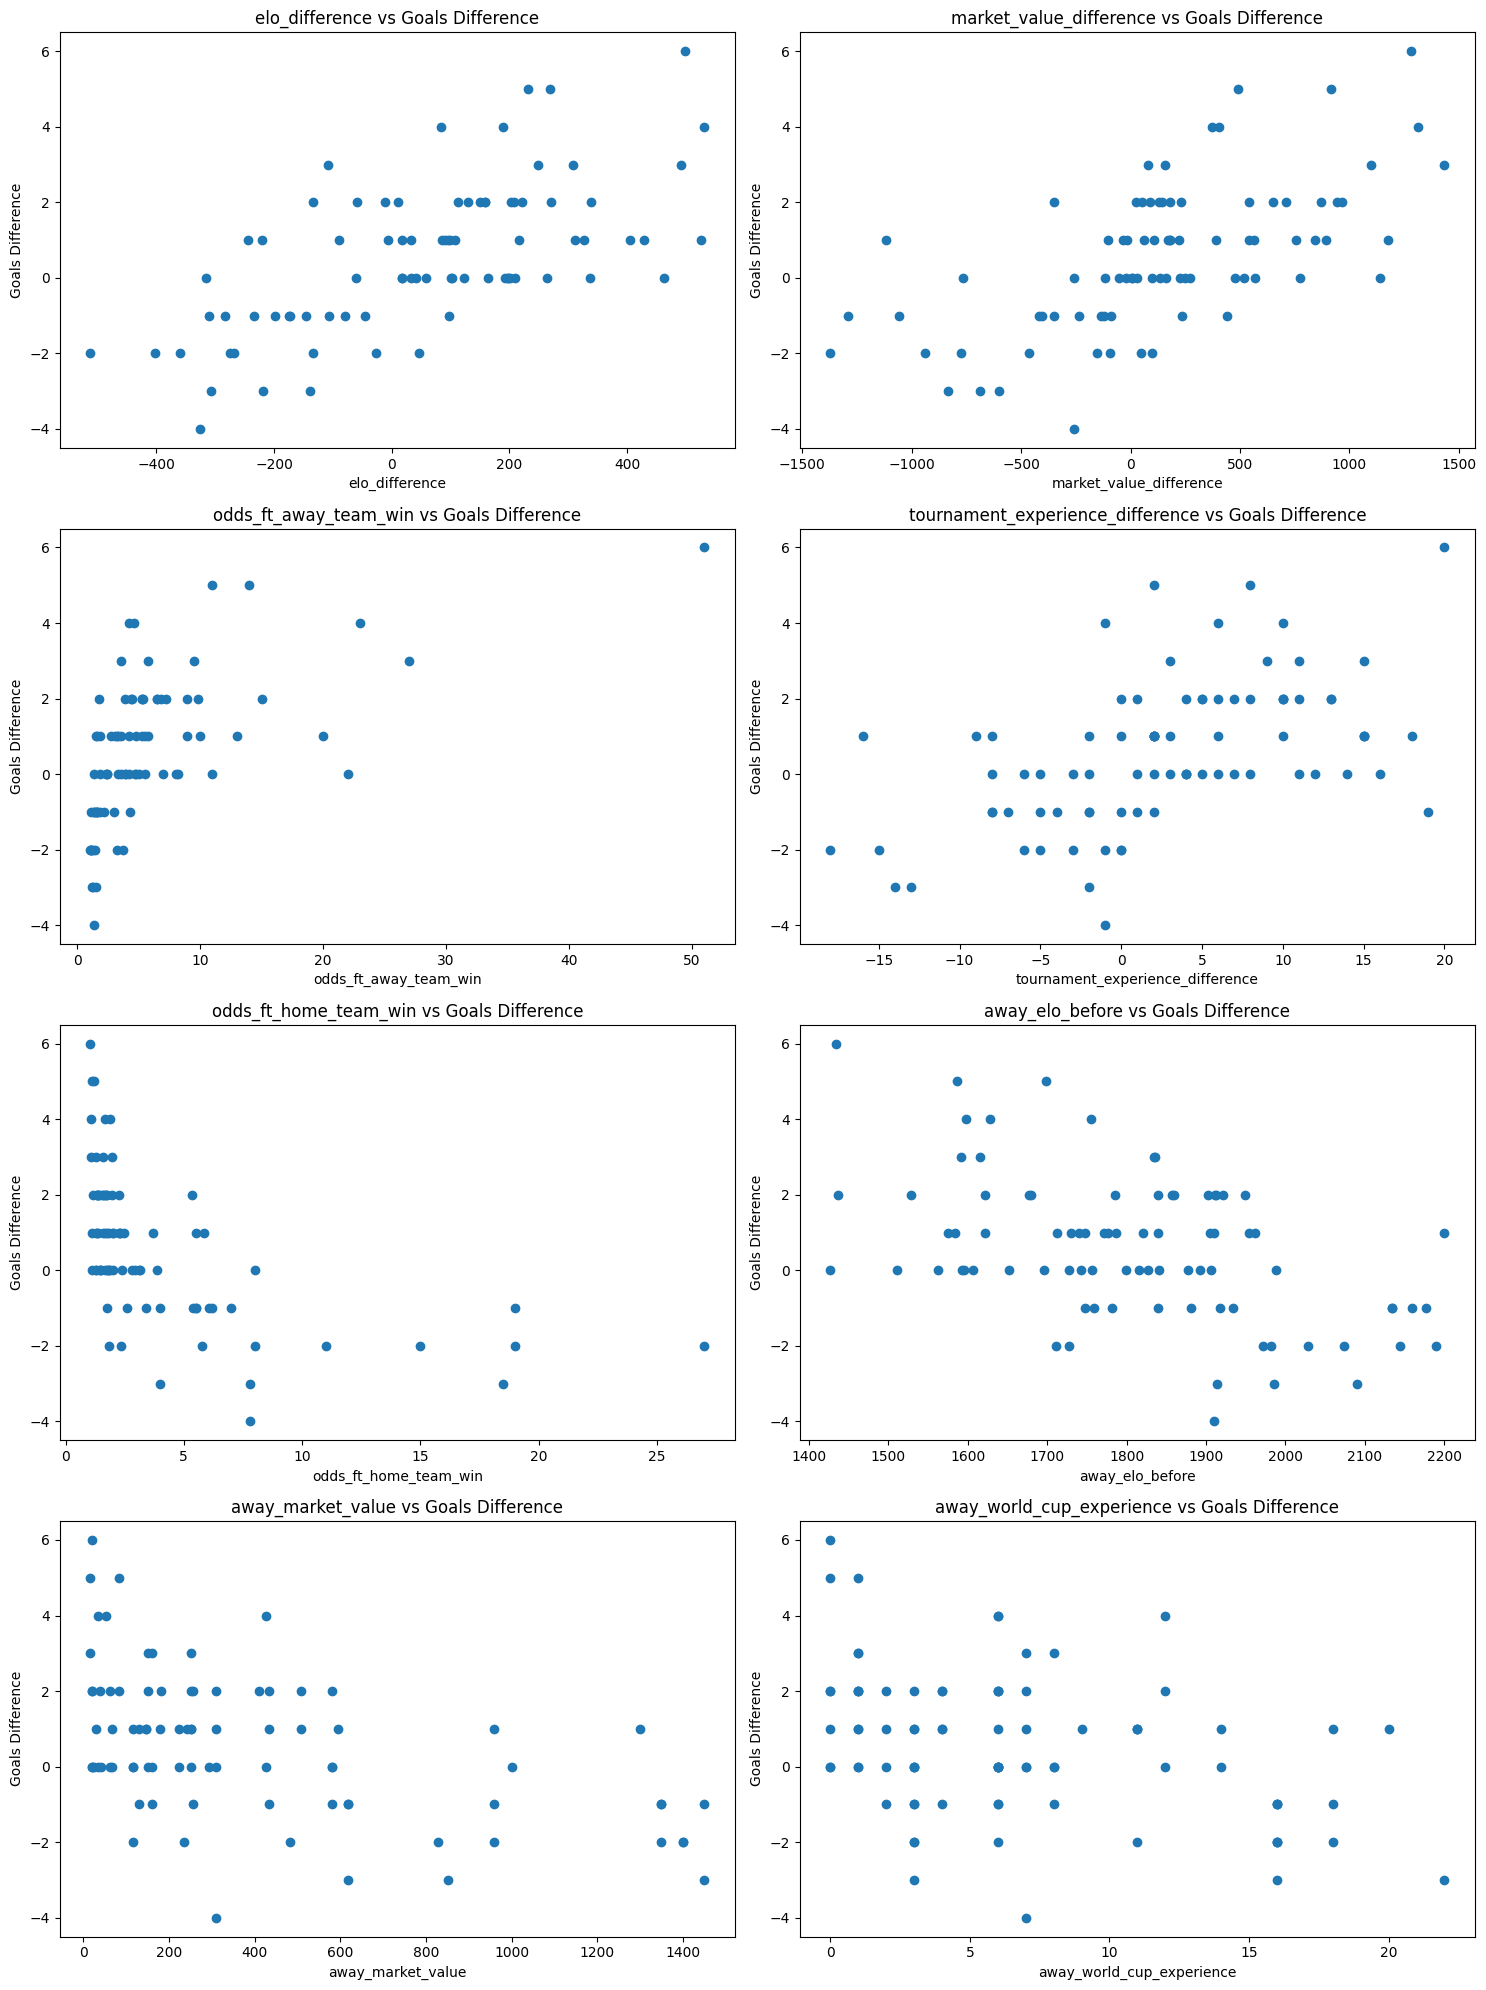

In [ ]:
fig, axes = plt.subplots(int(np.ceil(len(feature_cols) / 2)), 2, figsize=(15, 5 * int(np.ceil(len(feature_cols) / 2))))

for ax, variable in zip(axes.flatten(), feature_cols):
    ax.scatter(X_train_cur[variable], y_train_cur)
    ax.set_xlabel(variable)
    ax.set_ylabel('Goals Difference')
    ax.set_title(f'{variable} vs Goals Difference')

plt.tight_layout()
plt.show()

Most plots are a loose upward or downward cloud around a straight line. The two odds variables are a little bent (their rank correlation with goals difference is about 0.69, against about 0.55 for the straight-line Pearson r), but they are also strongly skewed, which the Yeo-Johnson step below handles. So we add no extra non-linear terms.

In [ ]:
# Decision: no non-linear transformation needed, so the data passes through unchanged.
model, _ = fit_and_evaluate('2. + Non-linear check (no change)', X_train_cur, y_train_cur, X_test_cur, y_test)

## Optimization 3: Check for multicollinearity

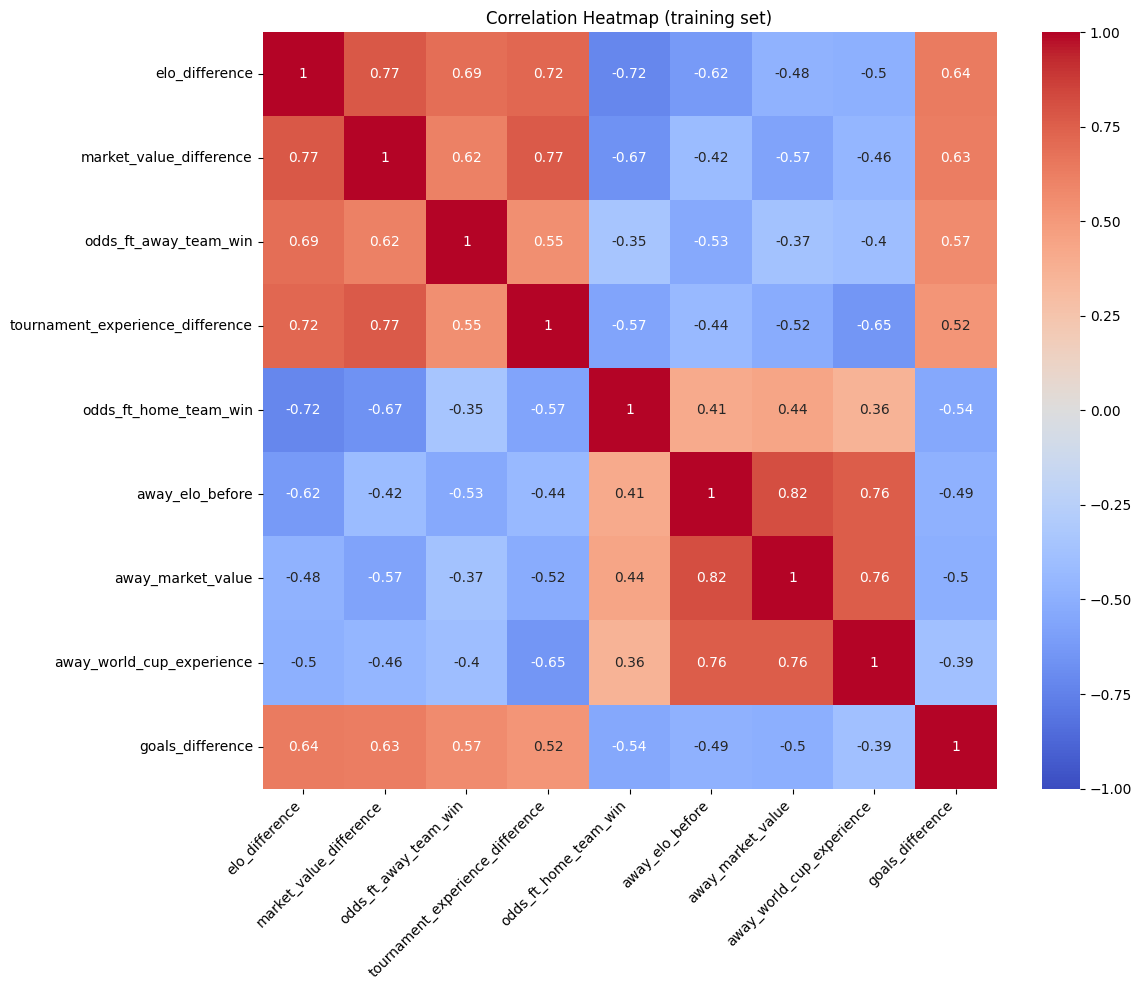

Highest pairwise correlation between features: 0.817


In [ ]:
corr_df = pd.concat([X_train_cur, y_train_cur], axis=1)

plt.figure(figsize=(12, 10))
sns.heatmap(corr_df.corr(), vmin=-1, vmax=1, center=0, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap (training set)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

feat_corr = X_train_cur.corr().abs().where(~np.eye(len(feature_cols), dtype=bool))
print("Highest pairwise correlation between features:", round(feat_corr.max().max(), 3))

The strongest correlation between two features is printed above (about 0.82). It is high, because Elo, market value, World Cup experience and the bookmaker odds all measure team strength, but the highest VIF in the selected set is 8.7, below the limit of 10 used in the selection. We therefore keep all eight variables. The individual coefficients of these correlated variables should be read with care.

In [ ]:
model, _ = fit_and_evaluate('3. + Multicollinearity check', X_train_cur, y_train_cur, X_test_cur, y_test)

## Optimization 4: Gaussian transformation (Yeo-Johnson)

In [ ]:
X_train_before_yj = X_train_cur.copy()
yj = PowerTransformer(method='yeo-johnson', standardize=False)

X_train_cur = pd.DataFrame(yj.fit_transform(X_train_cur),
                           index=X_train_cur.index, columns=X_train_cur.columns)
X_test_cur  = pd.DataFrame(yj.transform(X_test_cur),
                           index=X_test_cur.index, columns=X_test_cur.columns)

skew_before = X_train_before_yj.skew()
skew_after  = X_train_cur.skew()

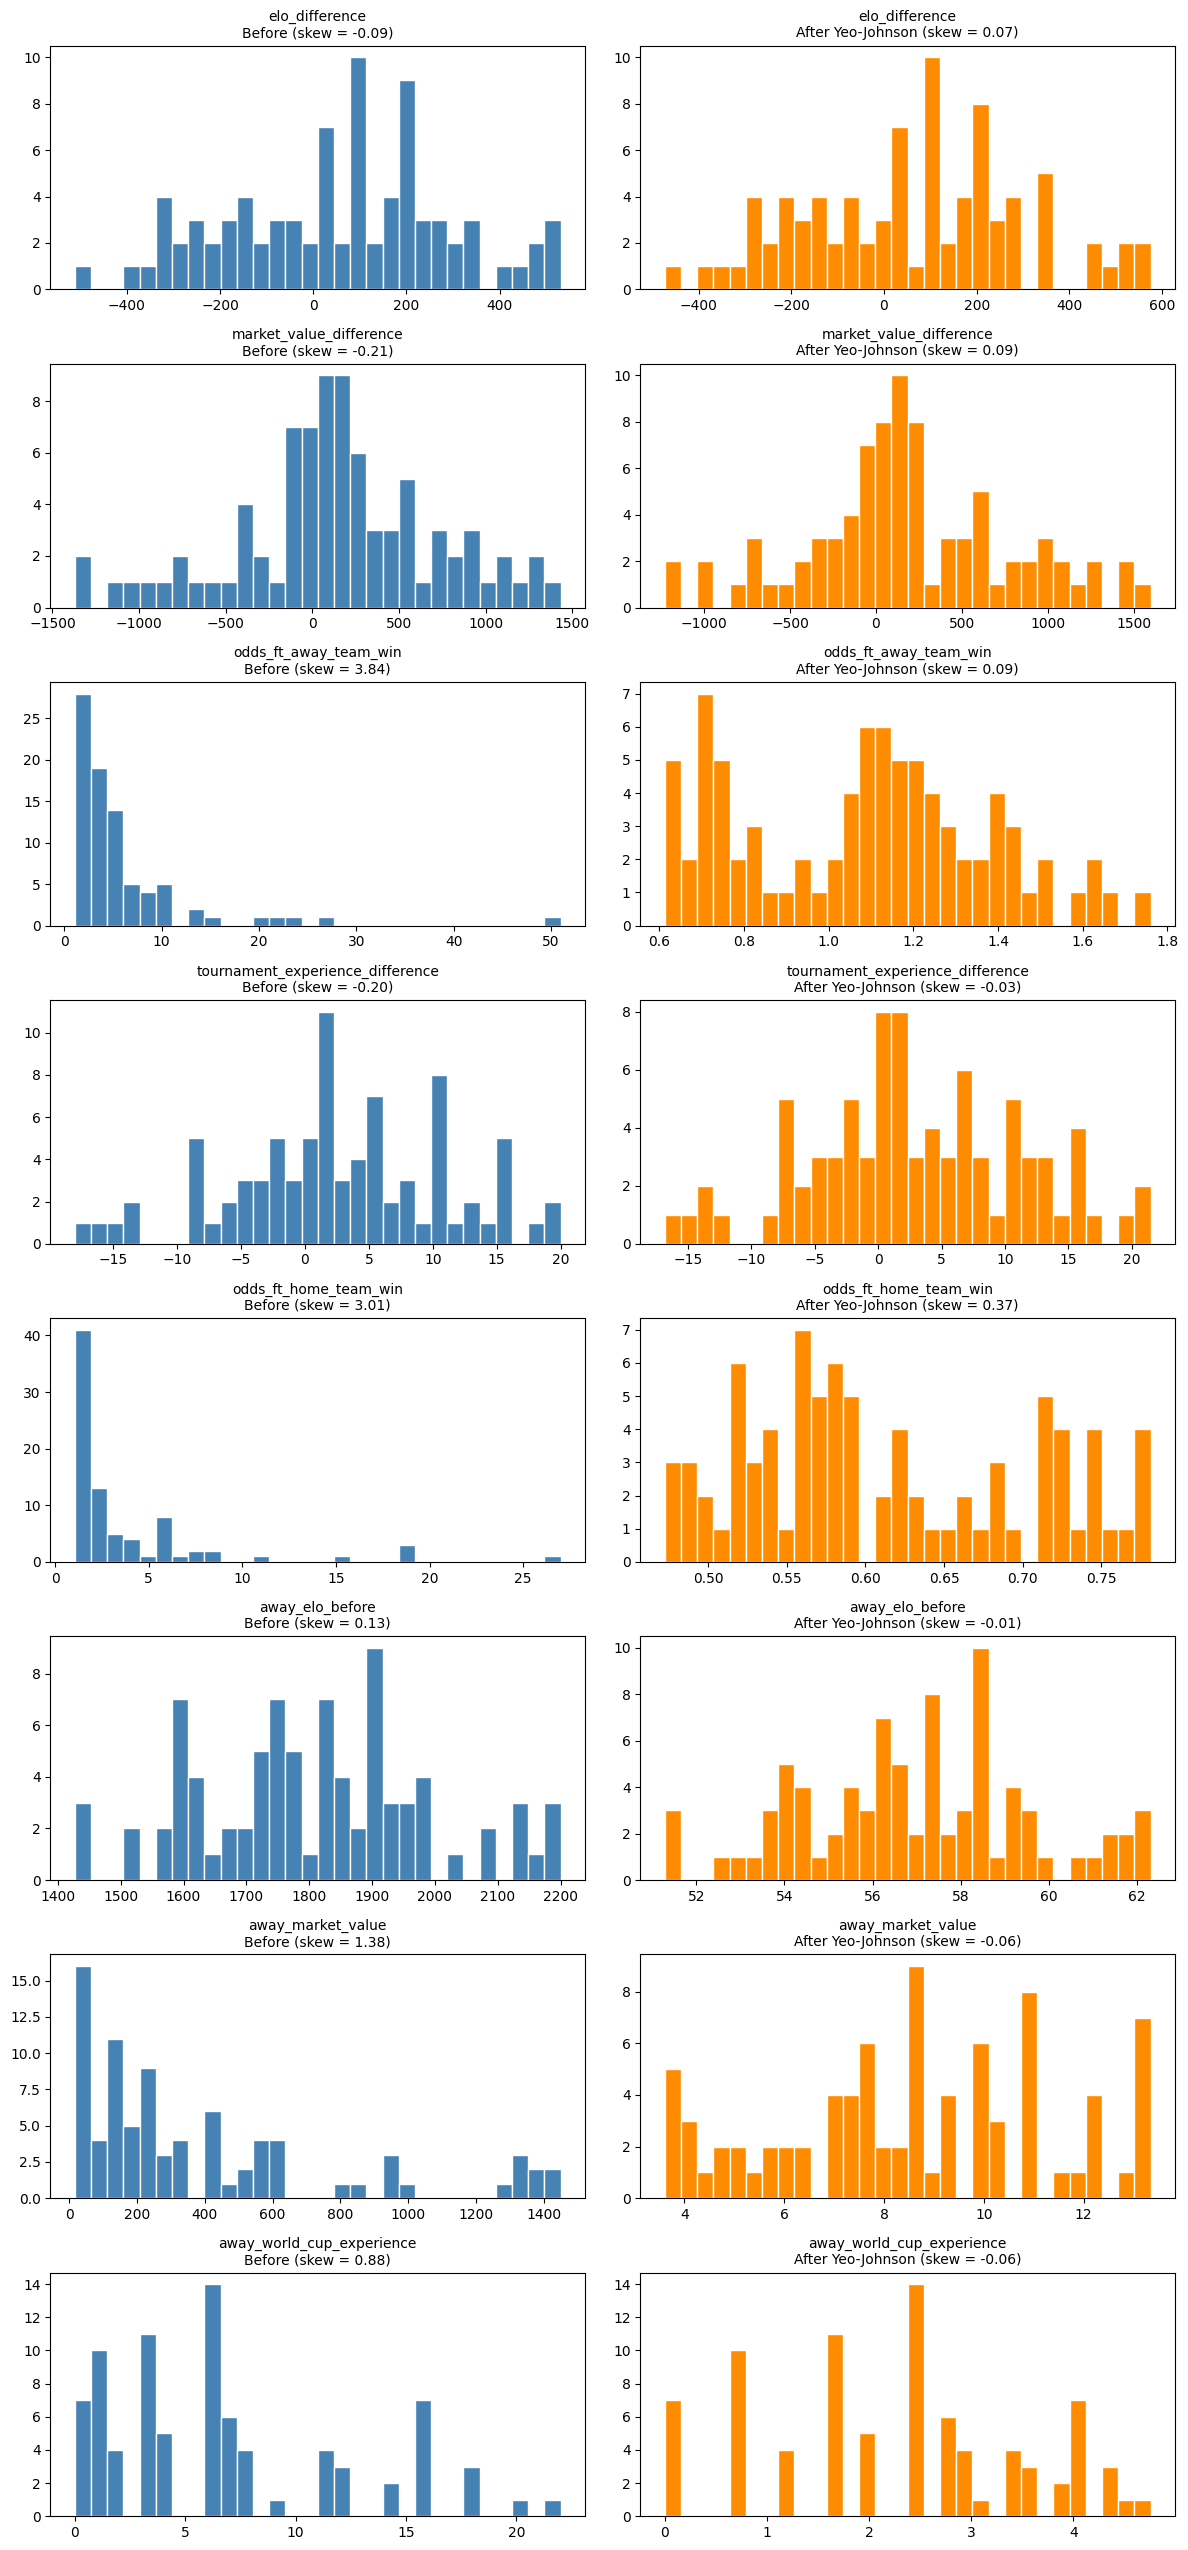

In [ ]:
# --------------------------------------------------
# HISTOGRAM OF EVERY VARIABLE: BEFORE vs AFTER YEO-JOHNSON
# --------------------------------------------------
fig, axes = plt.subplots(len(feature_cols), 2, figsize=(12, 3.2 * len(feature_cols)))

for i, var in enumerate(feature_cols):
    axes[i, 0].hist(X_train_before_yj[var], bins=30, color='steelblue', edgecolor='white')
    axes[i, 0].set_title(f'{var}\nBefore (skew = {skew_before[var]:.2f})', fontsize=10)

    axes[i, 1].hist(X_train_cur[var], bins=30, color='darkorange', edgecolor='white')
    axes[i, 1].set_title(f'{var}\nAfter Yeo-Johnson (skew = {skew_after[var]:.2f})', fontsize=10)

plt.tight_layout()
plt.show()

In [ ]:
model, _ = fit_and_evaluate('4. + Yeo-Johnson', X_train_cur, y_train_cur, X_test_cur, y_test)
print_equation(model, "Goals Difference")


Regression equation:
Goals Difference = 8.0137 - 0.0014 (elo_difference) + 0.0006 (market_value_difference) + 2.7068 (odds_ft_away_team_win) - 0.0078 (tournament_experience_difference) - 5.4379 (odds_ft_home_team_win) - 0.1195 (away_elo_before) - 0.0790 (away_market_value) + 0.1859 (away_world_cup_experience)


## Optimization 5: Z-standardisation

In [ ]:
zs = StandardScaler()

X_train_cur = pd.DataFrame(zs.fit_transform(X_train_cur),
                           index=X_train_cur.index, columns=X_train_cur.columns)
X_test_cur  = pd.DataFrame(zs.transform(X_test_cur),
                           index=X_test_cur.index, columns=X_test_cur.columns)

final_model, final_pred_te = fit_and_evaluate('5. + Z-standardisation', X_train_cur, y_train_cur, X_test_cur, y_test)
print_equation(final_model, "Goals Difference")


Regression equation:
Goals Difference = 0.5422 - 0.3371 (elo_difference) + 0.3309 (market_value_difference) + 0.7843 (odds_ft_away_team_win) - 0.0656 (tournament_experience_difference) - 0.4812 (odds_ft_home_team_win) - 0.3083 (away_elo_before) - 0.2168 (away_market_value) + 0.2381 (away_world_cup_experience)


## Test-set evaluation of the final model

,Train R2,Test R2,Test RMSE,Test MAE
Stage,,,,
0. Baseline,0.5152,0.2889,1.9802,1.4888
1. + Outlier removal,0.5152,0.2889,1.9802,1.4888
2. + Non-linear check (no change),0.5152,0.2889,1.9802,1.4888
3. + Multicollinearity check,0.5152,0.2889,1.9802,1.4888
4. + Yeo-Johnson,0.5286,0.4008,1.8178,1.3908
5. + Z-standardisation,0.5286,0.4008,1.8178,1.3908


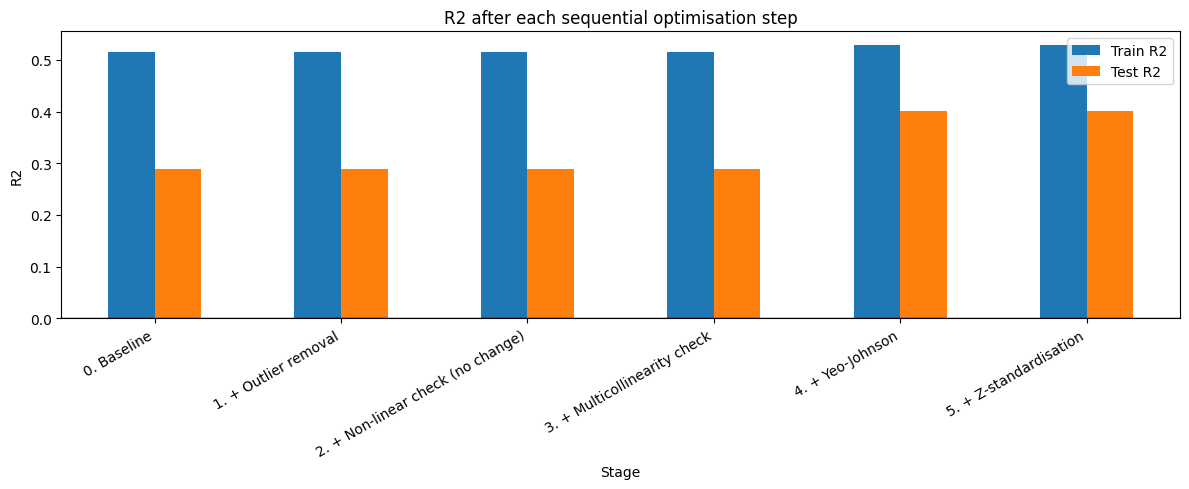

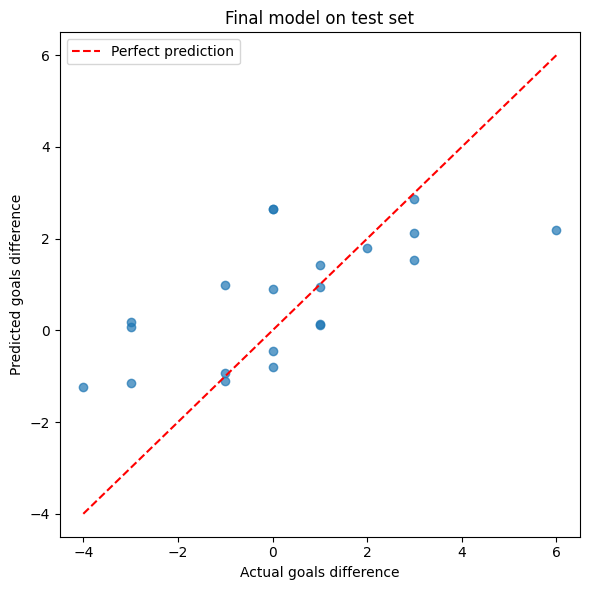

                                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
const                                0.5422      0.153      3.546      0.001       0.237       0.847
elo_difference                      -0.3371      0.517     -0.652      0.517      -1.368       0.694
market_value_difference              0.3309      0.322      1.029      0.307      -0.310       0.972
odds_ft_away_team_win                0.7843      0.867      0.905      0.369      -0.943       2.512
tournament_experience_difference    -0.0656      0.298     -0.220      0.827      -0.660       0.529
odds_ft_home_team_win               -0.4812      0.760     -0.633      0.529      -1.996       1.034
away_elo_before                     -0.3083      0.452     -0.682      0.497      -1.209       0.592
away_market_value                   -0.2168      0.370     -0.586      0.559      -0.954   

In [ ]:
results_df = pd.DataFrame(results).set_index('Stage').round(4)
display(results_df)

# R2 per stage (train vs test)
results_df[['Train R2', 'Test R2']].plot(kind='bar', figsize=(12, 5))
plt.axhline(0, color='black', linewidth=1)
plt.title('R2 after each sequential optimisation step')
plt.ylabel('R2')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

# Final model: predicted vs actual on the 20% test set
plt.figure(figsize=(6, 6))
plt.scatter(y_test, final_pred_te, alpha=0.7)
lims = [min(y_test.min(), final_pred_te.min()), max(y_test.max(), final_pred_te.max())]
plt.plot(lims, lims, 'r--', label='Perfect prediction')
plt.xlabel('Actual goals difference')
plt.ylabel('Predicted goals difference')
plt.title('Final model on test set')
plt.legend()
plt.tight_layout()
plt.show()

print(final_model.summary().tables[1])

**Conclusion.** The 8 variables chosen by the EDA from the 53 variables available before the match are `elo_difference`, `market_value_difference`, `odds_ft_away_team_win`, `tournament_experience_difference`, `odds_ft_home_team_win`, `away_elo_before`, `away_market_value` and `away_world_cup_experience`: all team-strength measures (Elo, squad value, World Cup experience, bookmaker odds).

* Before the transformations, the model explains about 52% of the variance on the training matches and about 29% on the unseen 20% test set (RMSE ≈ 1.98 goals).
* Outlier removal, the non-linear check and the multicollinearity check change nothing: no training match is flagged as an outlier, and no variable is removed.
* Yeo-Johnson raises the test R² to about 0.40 (RMSE ≈ 1.82). The odds variables are the most skewed, so this is plausible, but with only 21 test matches the gain should be read as indicative, not exact. Z-standardisation does not change the fit; it only puts the coefficients on a comparable scale.
* In the standardised model the largest effects are `odds_ft_away_team_win` and `odds_ft_home_team_win`, followed by `elo_difference`, `market_value_difference` and `away_elo_before`. These variables overlap heavily, so their individual signs are not reliable.
* None of the recent-form variables (goals, shots, possession, clean sheets) made the top 8: the team-strength variables have much stronger correlations with goals difference.

## Comparison with other scikit-learn regression models

The final OLS model is compared with other regressors from scikit-learn. Every model gets **exactly the same data**: the fully optimised training set (outliers removed, Yeo-Johnson, z-standardisation) and the same untouched 20% test set. A mean-only `DummyRegressor` shows what "no skill" looks like. Because the test set has only 21 matches, we also report a **5-fold cross-validated RMSE on the training set**, which is less dependent on one lucky split.

In [ ]:
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import KFold, cross_val_score

models = {
    'Mean baseline (no skill)': DummyRegressor(),
    'Ridge': RidgeCV(alphas=np.logspace(-2, 3, 30)),
    'Lasso': LassoCV(cv=5, random_state=42, max_iter=20000),
    'Elastic Net': ElasticNetCV(cv=5, random_state=42, max_iter=20000),
    'Random forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42),
    'Gradient boosting': GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=42),
    'Support vector (RBF)': SVR(kernel='rbf', C=1.0),
    'k-nearest neighbours (k=10)': KNeighborsRegressor(n_neighbors=10),
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
rows, preds = [], {}
for name, est in models.items():
    m = clone(est).fit(X_train_cur, y_train_cur)
    pred_tr, pred_te = m.predict(X_train_cur), m.predict(X_test_cur)
    cv_rmse = -cross_val_score(clone(est), X_train_cur, y_train_cur, cv=kf, scoring='neg_root_mean_squared_error').mean()
    preds[name] = pred_te
    rows.append({'Model': name, 'Train R2': r2_score(y_train_cur, pred_tr), 'Test R2': r2_score(y_test, pred_te),
                 'Test RMSE': np.sqrt(mean_squared_error(y_test, pred_te)), 'Test MAE': mean_absolute_error(y_test, pred_te)})

# the statsmodels OLS from the optimisation steps, for reference
rows.append({'Model': 'OLS (statsmodels, final model above)', 'Train R2': results[-1]['Train R2'], 'Test R2': results[-1]['Test R2'],
             'Test RMSE': results[-1]['Test RMSE'], 'Test MAE': results[-1]['Test MAE']})

comparison = pd.DataFrame(rows).set_index('Model').sort_values('Test RMSE').round(4)
display(comparison)

,Train R2,Test R2,Test RMSE,Test MAE
Model,,,,
Lasso,0.5150,0.4270,1.7776,1.3725
Elastic Net,0.5136,0.4191,1.7898,1.3735
Ridge,0.5068,0.4138,1.7979,1.3716
Support vector (RBF),0.5666,0.4087,1.8058,1.4179
"OLS (statsmodels, final model above)",0.5286,0.4008,1.8178,1.3908
k-nearest neighbours (k=10),0.4806,0.3659,1.8701,1.4857
Random forest,0.8019,0.2163,2.0789,1.5327
Gradient boosting,0.8775,0.2059,2.0926,1.6093
Mean baseline (no skill),0.0000,-0.0168,2.3680,1.8394


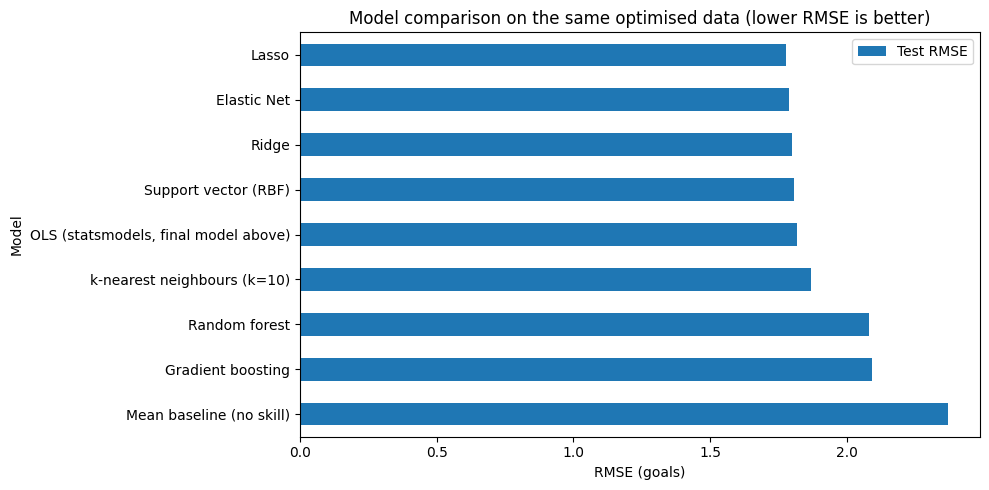

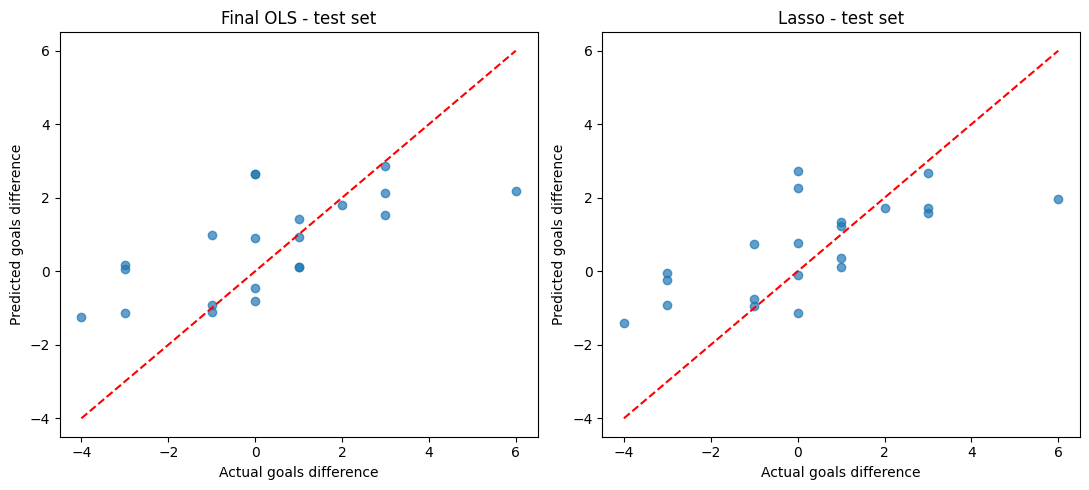

Best competing model on the test set: Lasso


In [ ]:
# Test RMSE and cross-validated RMSE per model (lower is better)
plot_df = comparison[['Test RMSE']].iloc[::-1]
plot_df.plot(kind='barh', figsize=(10, 5))
plt.title('Model comparison on the same optimised data (lower RMSE is better)')
plt.xlabel('RMSE (goals)')
plt.tight_layout()
plt.show()

# Predicted vs actual on the 20% test set for the best model and the final OLS
best_name = comparison.drop(index=['OLS (statsmodels, final model above)', 'Mean baseline (no skill)'])['Test RMSE'].idxmin()
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (title, p) in zip(axes, [('Final OLS', final_pred_te), (best_name, preds[best_name])]):
    ax.scatter(y_test, p, alpha=0.7)
    lims = [min(y_test.min(), np.min(p)), max(y_test.max(), np.max(p))]
    ax.plot(lims, lims, 'r--')
    ax.set(title=f'{title} - test set', xlabel='Actual goals difference', ylabel='Predicted goals difference')
plt.tight_layout()
plt.show()
print("Best competing model on the test set:", best_name)

* **Comparison with other scikit-learn models:** on the same optimised data, the penalised linear models (Lasso, Elastic Net, Ridge) are slightly better than plain OLS on the test set (test RMSE about 1.78 to 1.80 against 1.82; cross-validated RMSE about 1.41 to 1.42 against 1.50). Random forest and gradient boosting fit the training set very closely (train R² 0.80 and 0.88) but are the worst on unseen matches (test R² about 0.21 to 0.22), so they over-fit with only 83 training matches. All models beat the mean-only baseline (RMSE 2.37). The differences between the top models are small compared with the noise of a 21-match test set.